# Day 4 - RNN-LSTM and the soft-voting ensemble (Member A)

Steps:
1. load the data from Day 2
2. build, train, measure and save the RNN-LSTM
3. build the soft-voting ensemble from the DNN, CNN and LSTM
4. compare all four models
5. test the ensemble object that Member B will use

The LSTM is the slowest model to train. Do not close VS Code while a cell shows `[*]`.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath("../src"))
import train_models as tm
import lstm_ensemble as le

print("Ready")

Ready


## Settings

- `EPOCHS`: the most epochs the LSTM can train for. Early stopping usually stops sooner.
  If training is too slow on your laptop, lower it to 15.
- `WEIGHT_MODE`: the same class-weight setting as Day 3. Keep it the same so the models can be compared fairly.

In [2]:
EPOCHS = 30
BATCH_SIZE = 256
WEIGHT_MODE = "sqrt"

## 1. Load the data and the class weights

In [3]:
data, class_names, raw_weights = tm.load_data()
class_weight = tm.make_class_weights(raw_weights, WEIGHT_MODE)

n_features = data["X_train"].shape[1]
n_classes = len(class_names)
print("Features:", n_features, "| Classes:", n_classes)

# the LSTM reads the features as a sequence, so it needs shape (rows, 30, 1)
Xtr = tm.reshape_for_cnn(data["X_train"])
Xva = tm.reshape_for_cnn(data["X_val"])
Xte = tm.reshape_for_cnn(data["X_test"])
print(Xtr.shape, Xva.shape, Xte.shape)

Features: 30 | Classes: 10
(91579, 30, 1) (16161, 30, 1) (82332, 30, 1)


## 2. RNN-LSTM

An LSTM (Long Short-Term Memory) is a recurrent network with memory cells. It reads the 30 features one after another and keeps a memory of what it has seen, which can capture relationships between features.
Here: one LSTM layer with 64 units, then Dropout and two Dense layers. The last layer gives 10 probabilities.

In [4]:
tm.set_seed()
lstm = le.build_lstm(n_features, n_classes)
lstm.summary()

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,706 (84.79 KB)

 Trainable params: 21,706 (84.79 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
lstm_history = tm.train_model(
    lstm, Xtr, data["y_train"], Xva, data["y_val"],
    class_weight, EPOCHS, BATCH_SIZE,
)
print("Epochs run:", len(lstm_history["loss"]))

Epoch 1/30
358/358 - 21s - 59ms/step - accuracy: 0.5274 - loss: 1.4344 - val_accuracy: 0.6116 - val_loss: 1.1724 - learning_rate: 0.0010
Epoch 2/30
358/358 - 19s - 52ms/step - accuracy: 0.6405 - loss: 1.1506 - val_accuracy: 0.6759 - val_loss: 0.9787 - learning_rate: 0.0010
Epoch 3/30
358/358 - 16s - 46ms/step - accuracy: 0.6710 - loss: 1.0590 - val_accuracy: 0.6792 - val_loss: 0.9665 - learning_rate: 0.0010
Epoch 4/30
358/358 - 20s - 55ms/step - accuracy: 0.6787 - loss: 1.0175 - val_accuracy: 0.6919 - val_loss: 0.8937 - learning_rate: 0.0010
Epoch 5/30
358/358 - 22s - 60ms/step - accuracy: 0.6850 - loss: 0.9871 - val_accuracy: 0.6948 - val_loss: 0.8659 - learning_rate: 0.0010
Epoch 6/30
358/358 - 16s - 45ms/step - accuracy: 0.6881 - loss: 0.9599 - val_accuracy: 0.6922 - val_loss: 0.8453 - learning_rate: 0.0010
Epoch 7/30
358/358 - 21s - 58ms/step - accuracy: 0.6907 - loss: 0.9466 - val_accuracy: 0.7024 - val_loss: 0.8569 - learning_rate: 0.0010
Epoch 8/30
358/358 - 20s - 56ms/step - ac

### Measure the LSTM

In [6]:
lstm_val_probs = tm.predict_probs(lstm, Xva)
lstm_test_probs = tm.predict_probs(lstm, Xte)

lstm_val = tm.compute_metrics(data["y_val"], lstm_val_probs, class_names)
lstm_test = tm.compute_metrics(data["y_test"], lstm_test_probs, class_names)
tm.print_summary("lstm", lstm_val, lstm_test)


==== LSTM ====
             validation       test
accuracy               0.7205     0.6360
precision_weighted     0.7899     0.8162
recall_weighted        0.7205     0.6360
f1_weighted            0.7358     0.6794
f1_macro               0.4689     0.3586


In [7]:
rows = {c: lstm_test["per_class"][c] for c in class_names}
pd.DataFrame(rows).T[["precision", "recall", "f1-score", "support"]].round(3)

,precision,recall,f1-score,support
Analysis,0.072,0.483,0.125,677.0
Backdoor,0.058,0.268,0.095,583.0
DoS,0.356,0.021,0.039,4089.0
Exploits,0.662,0.546,0.598,11132.0
Fuzzers,0.233,0.737,0.354,6062.0
Generic,0.997,0.962,0.979,18871.0
Normal,0.997,0.573,0.728,37000.0
Reconnaissance,0.317,0.501,0.388,3496.0
Shellcode,0.095,0.376,0.151,378.0
Worms,0.211,0.091,0.127,44.0


### Save the LSTM

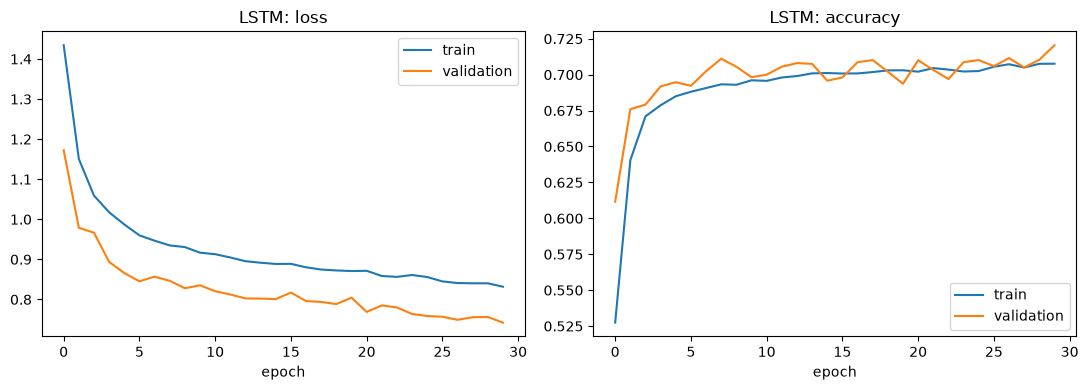

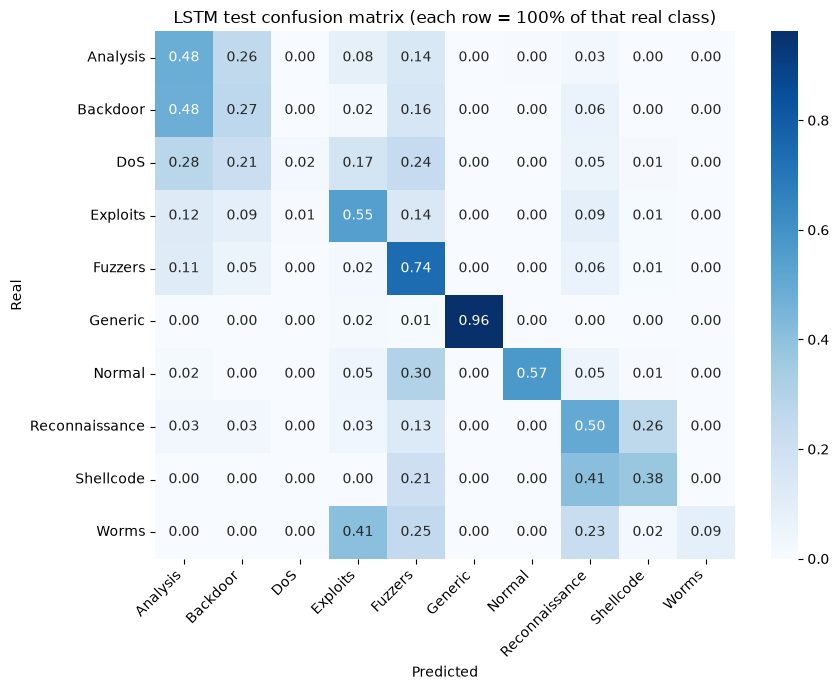

In [8]:
tm.save_results("lstm", lstm, lstm_history, lstm_val_probs, lstm_test_probs,
                lstm_val, lstm_test, class_names)
plt.show()

## 3. Soft-voting ensemble

Each model gives 10 probabilities for every record. Soft voting averages them, and the class with the highest average wins.
It works from the probabilities saved on Day 3 and above, so the three models must already be saved.

Example: for one record, DNN says 60% Exploits, CNN says 30% and LSTM says 45%. The average is 45%, which is compared with the averages of the other classes.

In [9]:
needed = ["dnn", "cnn", "lstm"]
for n in needed:
    print(n, "test probabilities saved:", (tm.PRED_DIR / (n + "_test_probs.npy")).is_file())

dnn test probabilities saved: True
cnn test probabilities saved: True
lstm test probabilities saved: True



==== ENSEMBLE ====
             validation       test
accuracy               0.7655     0.6577
precision_weighted     0.8361     0.8485
recall_weighted        0.7655     0.6577
f1_weighted            0.7835     0.7081
f1_macro               0.5527     0.4332


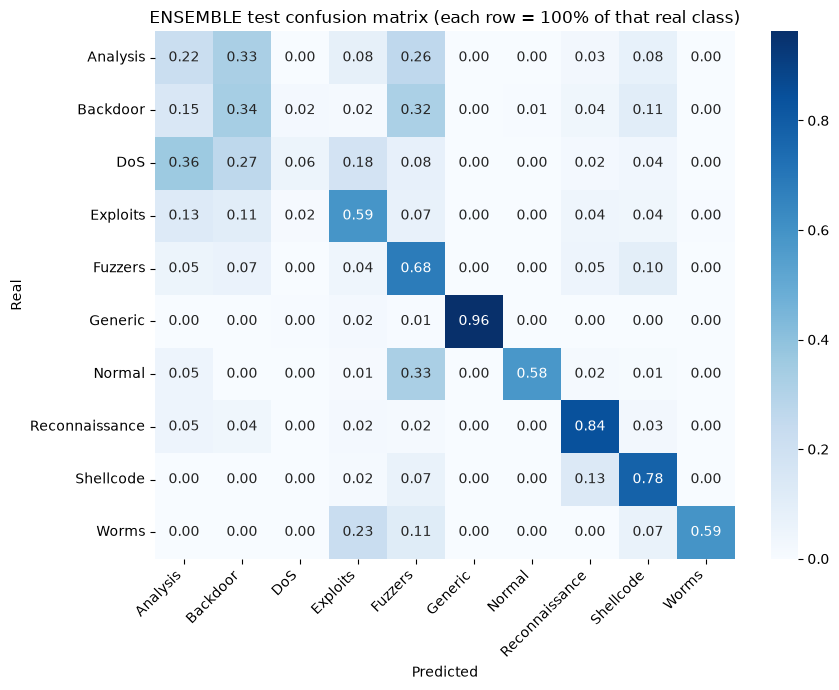

In [10]:
ens_val, ens_test = le.run_ensemble()
plt.show()

## 4. Compare all four models

In [11]:
def load_metrics(name):
    with open(tm.METRIC_DIR / (name + "_metrics.json")) as f:
        return json.load(f)

models = ["dnn", "cnn", "lstm", "ensemble"]
all_metrics = {m: load_metrics(m) for m in models}
keys = ["accuracy", "precision_weighted", "recall_weighted", "f1_weighted", "f1_macro"]

for split in ["test", "validation"]:
    table = pd.DataFrame(
        {m.upper(): [all_metrics[m][split][k] for k in keys] for m in models},
        index=keys).round(4)
    print("\n" + split.upper())
    display(table)


TEST


,DNN,CNN,LSTM,ENSEMBLE
accuracy,0.6510,0.6587,0.6360,0.6577
precision_weighted,0.8459,0.8372,0.8162,0.8485
recall_weighted,0.6510,0.6587,0.6360,0.6577
f1_weighted,0.7061,0.7084,0.6794,0.7081
f1_macro,0.4138,0.4222,0.3586,0.4332



VALIDATION


,DNN,CNN,LSTM,ENSEMBLE
accuracy,0.7589,0.7704,0.7205,0.7655
precision_weighted,0.8369,0.8332,0.7899,0.8361
recall_weighted,0.7589,0.7704,0.7205,0.7655
f1_weighted,0.7817,0.7883,0.7358,0.7835
f1_macro,0.5412,0.5508,0.4689,0.5527


In [12]:
f1 = pd.DataFrame(
    {m.upper(): [all_metrics[m]["test"]["per_class"][c]["f1-score"] for c in class_names]
     for m in models},
    index=class_names).round(3)
f1

,DNN,CNN,LSTM,ENSEMBLE
Analysis,0.034,0.059,0.125,0.048
Backdoor,0.109,0.079,0.095,0.102
DoS,0.121,0.109,0.039,0.098
Exploits,0.650,0.657,0.598,0.665
Fuzzers,0.342,0.327,0.354,0.344
Generic,0.977,0.980,0.979,0.981
Normal,0.732,0.742,0.728,0.733
Reconnaissance,0.755,0.694,0.388,0.736
Shellcode,0.208,0.255,0.151,0.234
Worms,0.210,0.320,0.127,0.391


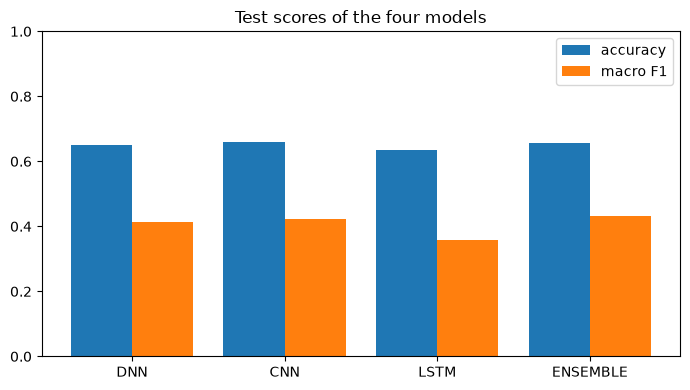

In [13]:
acc = [all_metrics[m]["test"]["accuracy"] for m in models]
f1m = [all_metrics[m]["test"]["f1_macro"] for m in models]
x = np.arange(len(models))
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, acc, 0.4, label="accuracy")
plt.bar(x + 0.2, f1m, 0.4, label="macro F1")
plt.xticks(x, [m.upper() for m in models])
plt.ylim(0, 1)
plt.title("Test scores of the four models")
plt.legend()
plt.tight_layout()
plt.savefig("figures/model_comparison_test.png", dpi=150)
plt.show()

## 5. Test the ensemble object for Member B

`load_ensemble()` loads the three saved models and the voting settings. Member B only needs `predict_proba` or `predict_labels`.

In [14]:
ens = le.load_ensemble()
sample = data["X_test"][:5]

print("Probabilities shape:", ens.predict_proba(sample).shape)
print("Predicted:", ens.predict_labels(sample))
print("Real     :", [class_names[i] for i in data["y_test"][:5]])

Probabilities shape: (5, 10)
Predicted: ['Shellcode', 'Fuzzers', 'Fuzzers', 'Fuzzers', 'Fuzzers']
Real     : ['Normal', 'Normal', 'Normal', 'Normal', 'Normal']


## What to check before moving on

- `models/lstm_model.h5`, `models/ensemble_config.json` and `models/metrics/ensemble_metrics.json` exist.
- The ensemble is at least as good as the best single model, or very close. If it is clearly worse, tell me.
- The comparison table is ready for your report.

## My notes (write in your own words)

- Which of the four models was best on the test set?
- Did the ensemble help? By how much?
- Which attack types are still hard to detect?